# Beginner walkthrough: the CNN–BiLSTM–Attention equations in code

This notebook is a **simplified, step-by-step** version of the code in this repository
(a reference implementation of my own paper, rebuilt in Python on synthetic data because the original data is confidential).
It runs on the **synthetic** SCADA-style dataset `data/synthetic/synthetic_scada.csv`,
so the numbers here are only a demo and **will differ from the paper's published results**.

Steps: 1) load data · 2) fill gaps and split · 3) scale · 4) make 24→1 windows ·
5) build the CNN–BiLSTM–Attention model · 6) short training run · 7) metrics · 8) plot.

Requirements: `numpy pandas scikit-learn torch matplotlib` (works in Anaconda on Windows, macOS, Linux, or Colab).

## 1. Load the data
We look for the CSV next to the repo first, then download it from GitHub (e.g. on Colab), and as a last resort generate a synthetic series right here.

In [1]:
import os, urllib.request
from pathlib import Path
import numpy as np, pandas as pd

FILE = "synthetic_scada.csv"
RAW_URL = "https://raw.githubusercontent.com/Rishabh-bgp/wind-forecasting-mathematical-formulations-validation/main/data/synthetic/" + FILE

def find_local():
    # works whether the notebook is started from the repo root or from notebooks/
    for base in (Path.cwd(), Path.cwd().parent):
        p = base / "data" / "synthetic" / FILE
        if p.exists():
            return p
    return None

local = find_local()
if local is not None:
    df = pd.read_csv(local); print("Loaded local file:", local)
else:
    try:  # e.g. on Google Colab
        df = pd.read_csv(RAW_URL); print("Downloaded:", RAW_URL)
    except Exception as e:
        print("Download failed (", e, ") -> generating synthetic data inline")
        df = None

if df is None:
    # inline synthetic generator: seasonal cycle + daily cycle + random noise
    rng = np.random.default_rng(42)
    idx = pd.date_range("2018-01-01", periods=8760, freq="h")
    doy, hour = idx.dayofyear.values, idx.hour.values
    seasonal = 0.6*np.cos(4*np.pi*(doy-350)/365) + 0.9*np.cos(2*np.pi*(doy-20)/365) - 0.6*np.exp(-((doy-205)/30)**2)
    diurnal = 0.8*np.sin(2*np.pi*(hour-9)/24)
    noise = np.zeros(len(idx)); eps = rng.gamma(2.0, 0.55, len(idx)) - 1.1
    for t in range(1, len(idx)): noise[t] = 0.85*noise[t-1] + eps[t]
    df = pd.DataFrame({"timestamp": idx, "wind_speed": np.clip(7.5+seasonal+diurnal+noise, 0, None)})

df["timestamp"] = pd.to_datetime(df["timestamp"])
df.head()

Loaded local file: /workspace/repos/wind-forecasting-mathematical-formulations-validation/data/synthetic/synthetic_scada.csv


,timestamp,wind_speed
0,2018-01-01 00:00:00,8.298
1,2018-01-01 01:00:00,8.630
2,2018-01-01 02:00:00,8.392
3,2018-01-01 03:00:00,8.124
4,2018-01-01 04:00:00,8.736


## 2. Fill gaps and split by time
Real SCADA data has small gaps; we fill them by **linear interpolation**. Then we split **chronologically**: the first 80 % of hours for training, the last 20 % for testing (never shuffle a time series — that would leak the future). To keep this demo fast we only use the first 3,000 hours.

In [2]:
s = df.set_index("timestamp")["wind_speed"].interpolate(limit_direction="both")
s = s.iloc[:3000]                      # demo only; the full scripts use all 8,760 hours
n_train = int(len(s) * 0.8)
train, test = s.iloc[:n_train], s.iloc[n_train:]
print(len(train), "training hours,", len(test), "test hours")

2400 training hours, 600 test hours


## 3. Scale to [0, 1]
The scaler is **fitted on the training part only**, then applied to everything, so no information from the test period leaks into training.

In [3]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler().fit(train.values.reshape(-1, 1))
scaled = scaler.transform(s.values.reshape(-1, 1)).ravel().astype("float32")

## 4. Make 24 → 1 windows
Each example uses the **previous 24 hours** as input. The target is the **change** from the last reading to the next hour, and the forecast is *last reading + predicted change*. Persistence is the special case where the predicted change is 0, so the model only has to learn how the wind will move away from now.

In [4]:
WINDOW = 24
def make_windows(v, w=WINDOW):
    X = np.array([v[i:i+w] for i in range(len(v)-w)], dtype="float32")
    y = np.array([v[i+w] for i in range(len(v)-w)], dtype="float32")
    return X, y

X_train, y_train = make_windows(scaled[:n_train])
X_test,  y_test  = make_windows(scaled[n_train-WINDOW:])   # test targets are only test hours
d_train = y_train - X_train[:, -1]          # target = change from the last reading
print(X_train.shape, X_test.shape)

(2376, 24) (600, 24)


## 5. The CNN–BiLSTM–Attention model
* **Conv1D** (64 filters, kernel 3) finds short local patterns (ramps, gusts).
* **BiLSTM** (64 units each way) reads the window forwards and backwards.
* **Soft attention** gives each time step a weight α and sums them into one context vector.
* **Dense** layer outputs the next-hour wind speed.

In [5]:
import torch, torch.nn as nn
torch.manual_seed(42)

class CNNBiLSTMAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv1d(1, 64, kernel_size=3)
        self.bilstm = nn.LSTM(64, 64, batch_first=True, bidirectional=True)
        self.W = nn.Linear(128, 64); self.v = nn.Linear(64, 1, bias=False)
        self.out = nn.Linear(128, 1)
    def forward(self, x):
        z = torch.relu(self.conv(x.unsqueeze(1))).transpose(1, 2)   # (batch, 22, 64)
        H, _ = self.bilstm(z)                                        # (batch, 22, 128)
        alpha = torch.softmax(self.v(torch.tanh(self.W(H))).squeeze(-1), dim=1)
        context = (alpha.unsqueeze(-1) * H).sum(dim=1)
        return self.out(context).squeeze(-1)

model = CNNBiLSTMAttention()
print(sum(p.numel() for p in model.parameters()), "trainable parameters")

75265 trainable parameters


## 6. A short training run
Adam (learning rate 0.001), MSE loss, batch size 32. The full script trains for up to 100 epochs with early stopping (patience 10); here we run **up to 20 epochs** with a simple early stop (patience 5 on a validation tail), which takes about a minute on a laptop CPU.

In [6]:
opt = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()
n_val = len(X_train) // 10                       # last 10 % of training windows = validation
Xt, yt = torch.tensor(X_train[:-n_val]), torch.tensor(d_train[:-n_val])
Xv, yv = torch.tensor(X_train[-n_val:]), torch.tensor(d_train[-n_val:])
best, wait, best_state = float("inf"), 0, None
for epoch in range(20):
    model.train(); perm = torch.randperm(len(Xt)); total = 0.0
    for i in range(0, len(Xt), 32):
        b = perm[i:i+32]
        opt.zero_grad(); loss = loss_fn(model(Xt[b]), yt[b]); loss.backward(); opt.step()
        total += loss.item() * len(b)
    model.eval()
    with torch.no_grad(): val = loss_fn(model(Xv), yv).item()
    print(f"epoch {epoch+1}: train MSE {total/len(Xt):.5f}  val MSE {val:.5f}")
    if val < best: best, wait, best_state = val, 0, {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= 5: print("early stop"); break
model.load_state_dict(best_state)

epoch 1: train MSE 0.00452  val MSE 0.00358


epoch 2: train MSE 0.00419  val MSE 0.00340


epoch 3: train MSE 0.00415  val MSE 0.00325


epoch 4: train MSE 0.00403  val MSE 0.00321


epoch 5: train MSE 0.00400  val MSE 0.00342


...

epoch 14: train MSE 0.00396  val MSE 0.00320


epoch 15: train MSE 0.00396  val MSE 0.00340


epoch 16: train MSE 0.00390  val MSE 0.00313


epoch 17: train MSE 0.00390  val MSE 0.00313
early stop


<All keys matched successfully>

## 7. Metrics on the test set (vs a persistence baseline)
Predictions are turned back into m/s with the same scaler, then we compute **MAE, RMSE, MAPE and R²**. We compare with **persistence** ('next hour = this hour'), the simplest baseline any forecaster must beat. *This is a short demo on synthetic data; the numbers are reported as they come out, even if the model loses to persistence.*

In [7]:
model.eval()
with torch.no_grad():
    change = model(torch.tensor(X_test)).numpy()
    pred = scaler.inverse_transform((X_test[:, -1] + change).reshape(-1, 1)).ravel()   # last reading + change
actual = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
persistence = scaler.inverse_transform(X_test[:, -1].reshape(-1, 1)).ravel()   # last observed hour

def metrics(name, y, p):
    err = y - p; m = y > 0.1
    print(f"{name:22s} MAE {np.mean(np.abs(err)):.3f} m/s | RMSE {np.sqrt(np.mean(err**2)):.3f} m/s | "
          f"MAPE {np.mean(np.abs(err[m]/y[m]))*100:.1f} % | R2 {1-np.sum(err**2)/np.sum((y-y.mean())**2):.3f}")

metrics("CNN-BiLSTM-Attention", actual, pred)
metrics("Persistence", actual, persistence)
rm, rp = np.sqrt(np.mean((actual-pred)**2)), np.sqrt(np.mean((actual-persistence)**2))
print("Model beats persistence on RMSE:" , "yes" if rm < rp else "no", f"({rm:.3f} vs {rp:.3f} m/s)")
print("Short demo on SYNTHETIC data - not comparable with the paper's published results.")

CNN-BiLSTM-Attention   MAE 0.584 m/s | RMSE 0.756 m/s | MAPE 8.1 % | R2 0.730
Persistence            MAE 0.612 m/s | RMSE 0.785 m/s | MAPE 8.4 % | R2 0.709
Model beats persistence on RMSE: yes (0.756 vs 0.785 m/s)
Short demo on SYNTHETIC data - not comparable with the paper's published results.


## 8. Plot actual vs predicted (first 7 days of the test set)

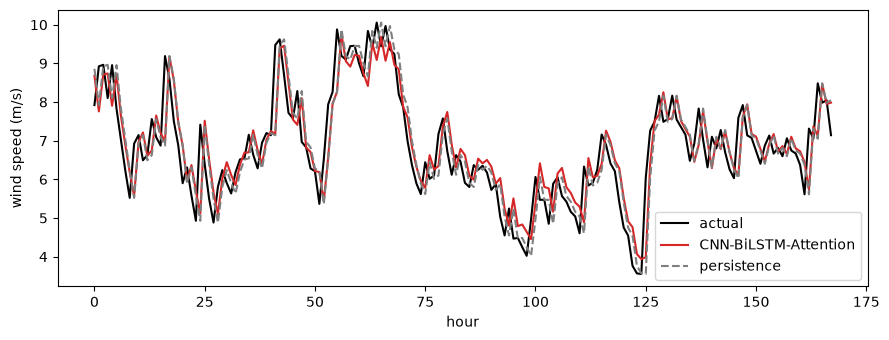

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 3.5))
plt.plot(actual[:168], label="actual", color="black")
plt.plot(pred[:168], label="CNN-BiLSTM-Attention", color="tab:red")
plt.plot(persistence[:168], label="persistence", color="tab:gray", ls="--")
plt.xlabel("hour"); plt.ylabel("wind speed (m/s)"); plt.legend(); plt.tight_layout(); plt.show()

## Next steps
Run `python train.py --config configs/default.yaml` for the full experiment with all baselines, Diebold–Mariano tests and residual diagnostics. To use your own data, see the **Data** section of the README.